# The Random Forest Rangers — Detailed EDA

German Accident Atlas 2025 · Presentation: 23 October 2026

**File 1 of 2.** We explore the data to understand patterns before building models. EDA means exploring data through tables and charts.

Run from the project folder containing `data/`. All cells have now been executed on the uploaded updated dataset, including the road-user combination analysis. Continue with `02_accident_modeling.ipynb` after reviewing the findings.

## The Machine Learning Workflow

### Define the Business Goal

**Suggested client:** a local or regional road-safety planning team. This is a proposed audience, not a confirmed client.

**Question:** Given that an injury accident has happened, how likely is it to involve serious or fatal injuries, based on the place, time, road conditions, lighting and road users involved?

The answer could help a road-safety team identify situations that deserve closer investigation. It cannot tell them where the next accident will happen or which change would prevent injuries.

Our answer is a probability, such as 20 out of 100 similar injury accidents. `severe = 0` means slight injury; `severe = 1` means serious or fatal injury. We do not use accident type, accident kind, IDs or administrative fields as prediction inputs. Federal state is retained as the agreed location input.

We have not agreed a minimum useful improvement or a decision threshold with a client. A better score alone does not prove the tool is ready for use.

### Get the Data

Use only `data/accidents_2025_with_population.csv`. The agreed version has 272,812 rows and 41 columns. Each row is one recorded injury accident. Keep municipality codes (`ags`) and accident IDs as text to preserve their format.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_FILE = Path("data/accidents_2025_with_population.csv")
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Cannot find {DATA_FILE}. Open notebook from the ML_project folder, "
        "or update DATA_FILE to the correct path."
    )

df = pd.read_csv(DATA_FILE, dtype={"ags": str, "accident_id": str})
print("Dataset shape:", df.shape)
print("Unique IDs:", df["accident_id"].nunique())
print("Duplicate IDs:", df["accident_id"].duplicated().sum())
assert df["accident_id"].is_unique
assert set(df["severe"].dropna().unique()) == {0, 1}

Dataset shape: (272812, 41)
Unique IDs: 272812
Duplicate IDs: 0


### First Look at the Data

Check the injury labels, count the outcomes and look for missing population information. Population density describes a whole municipality, not the exact road where an accident happened.

In [2]:
city_features = ["population", "area_km2", "population_per_km2"]

print("Severity categories and binary target:")
display(pd.crosstab(df["severity"], df["severe"], dropna=False))
print("\nBinary target counts:")
print(df["severe"].value_counts())
print("\nMissing city values:")
print(df[city_features].isna().sum())

assert not df[city_features].isna().any().any(), "Unexpected missing city values"
assert len(df) == 272812, "Dataset size differs from the agreed cleaned version"

Severity categories and binary target:


severe,0,1
severity,,
Accident with persons killed,0,2474
Accident with seriously injured,0,40371
Accident with slightly injured,229967,0



Binary target counts:
severe
0    229967
1     42845
Name: count, dtype: int64

Missing city values:
population            0
area_km2              0
population_per_km2    0
dtype: int64


### See the columns and missing values

This overview shows what information is available. It is a file check; the detailed pattern-finding below uses training data only.

In [3]:
display(df.head())
display(pd.DataFrame({
    "type": df.dtypes.astype(str),
    "missing": df.isna().sum(),
}).rename_axis("column"))

,accident_id,state,region,district,municipality,year,month,hour,weekday,severity,...,single_type,vulnerable_vs_vehicle,date,date_check,killed,ags,population,area_km2,population_per_km2,city_note
0,01250509171013352025,1,1-0,1-0-60,1-0-60-7,2025,5,15,Friday,Accident with slightly injured,...,1,0,2025-05-09,ok,0,01060007,1067.0,34.85,31.0,ok
1,01250405161013752025,1,1-0,1-0-62,1-0-62-53,2025,4,14,Saturday,Accident with slightly injured,...,1,0,2025-04-05,ok,0,01062053,9052.0,11.36,797.0,ok
2,01250118171013142025,1,1-0,1-0-56,1-0-56-15,2025,1,9,Saturday,Accident with slightly injured,...,1,0,2025-01-18,ok,0,01056015,51375.0,21.36,2405.0,ok
3,01250326152013912025,1,1-0,1-0-55,1-0-55-28,2025,3,16,Wednesday,Accident with slightly injured,...,0,1,2025-03-26,ok,0,01055028,10842.0,69.07,157.0,ok
4,01250225145013362025,1,1-0,1-0-58,1-0-58-116,2025,2,17,Tuesday,Accident with slightly injured,...,1,0,2025-02-25,ok,0,01058116,834.0,13.89,60.0,ok


,type,missing
column,,
accident_id,str,0
state,int64,0
region,str,0
district,str,0
municipality,str,0
year,int64,0
month,int64,0
hour,int64,0
weekday,str,0


## Clean the Data

The updated file was already prepared: 195 rows without municipality information were removed before this notebook. We do not remove them again or repeat earlier cleaning on an older file.

We check the agreed size, unique IDs, complete target, population values and injury labels. A failed check asks us to investigate; it does not silently change the data. Any calculation learned from the data, such as scaling values for a model, will use training rows only.

In [4]:
assert df.shape == (272812, 41), "Use the agreed updated dataset"
assert df["severe"].notna().all()
assert df["ags"].notna().all()
assert df["accident_id"].notna().all()
assert df["severe"].value_counts().to_dict() == {0: 229967, 1: 42845}
assert (df["population"] >= 0).all()
assert (df["area_km2"] > 0).all()
assert (df["population_per_km2"] >= 0).all()
print("The agreed data checks passed. No extra rows were removed.")

The agreed data checks passed. No extra rows were removed.


## Train-Validation-Test Split

We keep the agreed shuffled 70/15/15 split, using seed 42. Each part has nearly the same share of serious/fatal accidents. Training teaches the models; validation compares them; test is reserved for one final check after all choices are fixed.

Expected sizes: 190,968 training rows, 40,922 validation rows and 40,922 test rows. A teammate who split using the three original injury labels may have different accidents in each part, so their scores are not directly comparable.

In [5]:
from sklearn.model_selection import train_test_split

train, temporary = train_test_split(
    df, test_size=0.30, stratify=df["severe"], random_state=42
)
validation, test = train_test_split(
    temporary, test_size=0.50, stratify=temporary["severe"], random_state=42
)

# The test set is used only to verify that the split contains each ID once.
all_ids = pd.concat([train["accident_id"], validation["accident_id"], test["accident_id"]])
assert len(all_ids) == len(df)
assert all_ids.is_unique
assert set(all_ids) == set(df["accident_id"])

print("Training:", len(train), "| Validation:", len(validation), "| Test:", len(test))
print("\nSevere percentage (training and validation):")
display(pd.DataFrame({
    "split": ["train", "validation"],
    "accidents": [len(train), len(validation)],
    "severe_pct": [100 * train["severe"].mean(), 100 * validation["severe"].mean()]
}).round(2))

Training: 190968 | Validation: 40922 | Test: 40922

Severe percentage (training and validation):


,split,accidents,severe_pct
0,train,190968,15.70
1,validation,40922,15.71


### Keep the same accidents in each split

Both notebooks use the same file order, seed and splitting rules. If saved split files exist, verify their IDs against these groups. Do not overwrite a different split without checking why it differs. This check reads test IDs only, never test performance.

In [6]:
assert (len(train), len(validation), len(test)) == (190968, 40922, 40922)
split_dir = Path("data/splits_updated")
for name, part in [("train", train), ("validation", validation), ("test", test)]:
    candidates = [split_dir / f"{name}.csv", split_dir / f"{name}.csv.gz"]
    if name == "validation":
        candidates += [split_dir / "val.csv", split_dir / "val.csv.gz"]
    for saved_path in candidates:
        if saved_path.exists():
            saved_ids = pd.read_csv(saved_path, usecols=["accident_id"], dtype={"accident_id": str})
            assert saved_ids["accident_id"].is_unique
            assert set(saved_ids["accident_id"]) == set(part["accident_id"]), f"Split differs: {saved_path}"
            print(f"Verified IDs: {saved_path}")
print("Splits are ready. No files were overwritten.")

Splits are ready. No files were overwritten.


## Full EDA — What seems connected to serious injuries?

Before training models, we look at **all the scenario information** in the updated data: month, season, weekday, weekend, hour, night, lighting, road surface, road users, federal state, location and city population density.

We only use **training accidents** for these comparisons. In each chart we show the **percentage of injury accidents that were serious or fatal** — not the chance that an accident happens. Different groups can overlap, and a pattern does not prove its cause.

### First, what kinds of injuries are in the training data?

This is our starting point: how many accidents involved slight injuries, serious injuries or deaths? It helps us understand why simply predicting “not severe” would be misleading.

Accident outcomes (training only):


,accidents,percent
severity,,
Accident with slightly injured,160977,84.3
Accident with seriously injured,28268,14.8
Accident with persons killed,1723,0.9


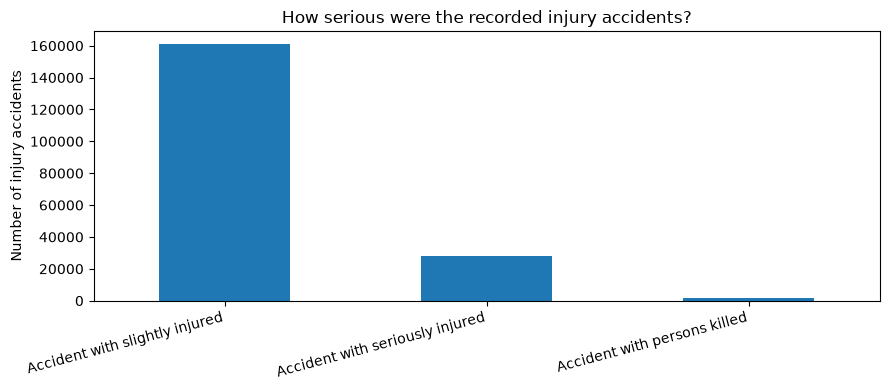

In [7]:
severity_order = ["Accident with slightly injured", "Accident with seriously injured", "Accident with persons killed"]
severity_counts = train["severity"].value_counts()
print("Accident outcomes (training only):")
display(pd.DataFrame({"accidents": severity_counts, "percent": (severity_counts / len(train) * 100).round(2)}))
fig, ax = plt.subplots(figsize=(9, 4))
severity_counts.reindex([x for x in severity_order if x in severity_counts.index] + [x for x in severity_counts.index if x not in severity_order]).plot.bar(ax=ax)
ax.set_title("How serious were the recorded injury accidents?")
ax.set_ylabel("Number of injury accidents")
ax.set_xlabel("")
plt.xticks(rotation=15, ha="right")
plt.tight_layout(); plt.show()

### Month and season

Do serious/fatal injuries make up a larger share of accidents in some months or seasons? We compare **percentages**, so busy months do not automatically look more dangerous.

,accidents,severe_pct
Jan,12268,14.44
Feb,10464,14.47
Mar,14414,15.94
Apr,16378,16.87
May,19373,16.42
Jun,19471,16.74
Jul,19385,16.47
Aug,18420,17.86
Sep,18192,15.44
Oct,15548,13.80


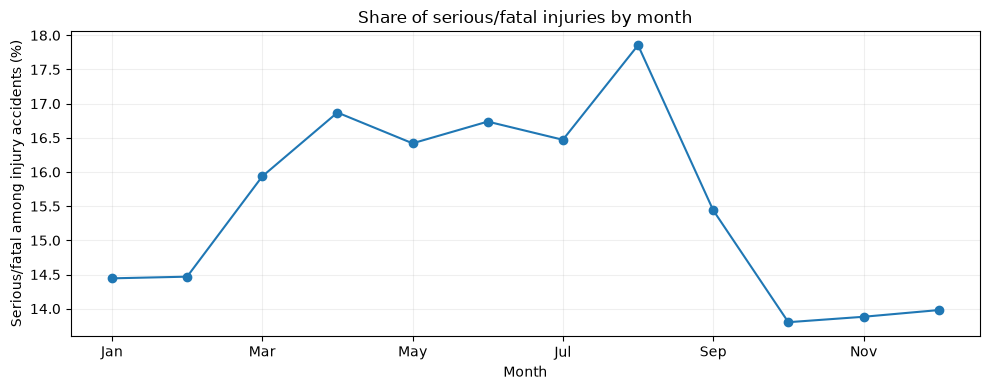

Seasons (calendar months, not actual weather):


,accidents,severe_pct
season,,
Winter,35250,14.29
Spring,50165,16.43
Summer,57276,17.01
Autumn,48277,14.44


In [8]:
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
month_summary = train.groupby("month")["severe"].agg(accidents="size", severe_pct="mean").reindex(range(1,13))
month_summary["severe_pct"] *= 100
month_summary.index = month_names
display(month_summary.round(2))
fig, ax = plt.subplots(figsize=(10,4))
month_summary["severe_pct"].plot(ax=ax, marker="o")
ax.set_title("Share of serious/fatal injuries by month")
ax.set_ylabel("Serious/fatal among injury accidents (%)")
ax.set_xlabel("Month")
ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

season_map = {12:"Winter",1:"Winter",2:"Winter",3:"Spring",4:"Spring",5:"Spring",6:"Summer",7:"Summer",8:"Summer",9:"Autumn",10:"Autumn",11:"Autumn"}
season_summary = train.assign(season=train["month"].map(season_map)).groupby("season")["severe"].agg(accidents="size", severe_pct="mean").reindex(["Winter","Spring","Summer","Autumn"])
season_summary["severe_pct"] *= 100
print("Seasons (calendar months, not actual weather):")
display(season_summary.round(2))

### Weekday versus weekend

We check whether the proportion of serious/fatal accidents changes by weekday. Then we compare weekdays with weekends. We use the **readable weekday names** in the new dataset, not the old numeric weekday codes.

Weekday labels present: ['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']


,accidents,severe_pct
weekday,,
Friday,30702,15.26
Monday,28856,14.36
Saturday,23935,17.87
Sunday,17969,19.86
Thursday,30241,15.27
Tuesday,30031,14.51
Wednesday,29234,14.85


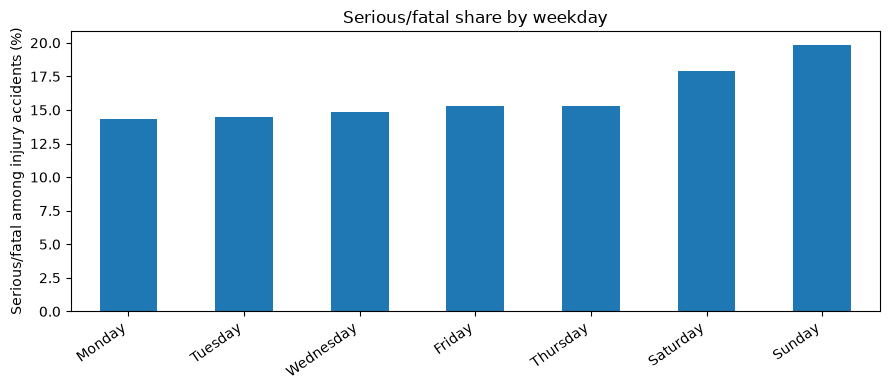

,accidents,severe_pct
day_group,,
Weekday,149064,14.86
Weekend,41904,18.72


In [9]:
print("Weekday labels present:", sorted(train["weekday"].dropna().astype(str).unique()))
weekday_text = train["weekday"].astype(str).str.strip().str.lower()
weekend_names = {"saturday", "sunday", "samstag", "sonntag", "sat", "sun"}
weekday_names = {"monday","tuesday","wednesday","thursday","friday","montag","dienstag","mittwoch","donnerstag","freitag","mon","tue","wed","thu","fri"}
unknown_weekdays = set(weekday_text.unique()) - (weekend_names | weekday_names)
if unknown_weekdays:
    print("Unrecognized weekday values:", sorted(unknown_weekdays))
    print("Please verify these labels before interpreting the weekend comparison.")
weekday_summary = train.groupby("weekday")["severe"].agg(accidents="size", severe_pct="mean")
weekday_summary["severe_pct"] *= 100
display(weekday_summary.round(2))
weekday_summary.sort_values("severe_pct")["severe_pct"].plot.bar(figsize=(9,4), title="Serious/fatal share by weekday")
plt.ylabel("Serious/fatal among injury accidents (%)"); plt.xlabel(""); plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()
if not unknown_weekdays:
    weekend_summary = train.assign(day_group=np.where(weekday_text.isin(weekend_names), "Weekend", "Weekday")).groupby("day_group")["severe"].agg(accidents="size", severe_pct="mean")
    weekend_summary["severe_pct"] *= 100
    display(weekend_summary.round(2))

### Accident hour and nighttime

We look at every hour of the day. We also make a simple night indicator: **22:00–05:59**. This is a clock-based grouping; it is not the same as the recorded lighting conditions.

,accidents,severe_pct
hour,,
0,1844,21.53
1,1476,23.51
2,1046,23.90
3,919,26.22
4,971,19.77
5,2724,17.62
6,5191,15.35
7,11455,11.76
8,8111,11.96


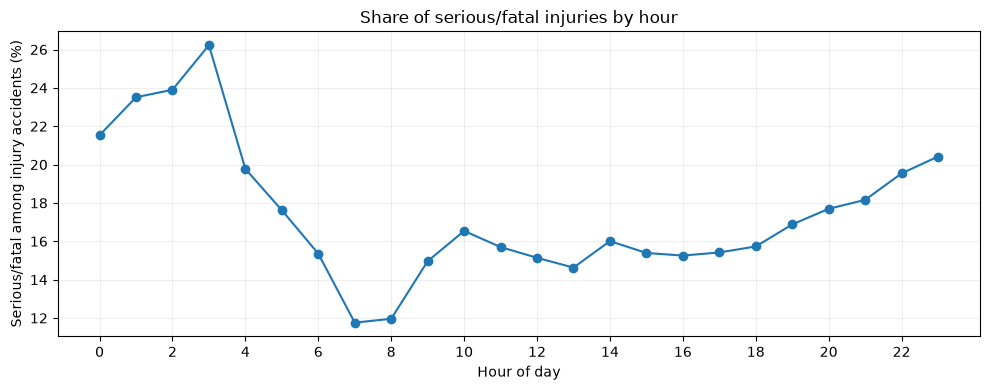

Night versus other hours:


,accidents,severe_pct
time_group,,
Night (22–05),15448,20.68
Other hours,175520,15.27


In [10]:
hour_summary = train.groupby("hour")["severe"].agg(accidents="size", severe_pct="mean").reindex(range(24))
hour_summary["severe_pct"] *= 100
display(hour_summary.round(2))
fig, ax = plt.subplots(figsize=(10,4))
hour_summary["severe_pct"].plot(ax=ax, marker="o")
ax.set_title("Share of serious/fatal injuries by hour")
ax.set_ylabel("Serious/fatal among injury accidents (%)"); ax.set_xlabel("Hour of day")
ax.set_xticks(range(0,24,2)); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()
night_summary = train.assign(time_group=np.where((train["hour"] >= 22) | (train["hour"] < 6), "Night (22–05)", "Other hours")).groupby("time_group")["severe"].agg(accidents="size", severe_pct="mean")
night_summary["severe_pct"] *= 100
print("Night versus other hours:")
display(night_summary.round(2))

### Lighting and road surface

Next, we compare the recorded lighting and road-surface categories. These are **assumed conditions** in our scenario model, not proof that a condition itself causes severe injuries.


Lighting


,accidents,severe_pct
light,,
darkness,35482,17.46
twilight,9726,15.44
daylight,145760,15.29



Road surface


,accidents,severe_pct
road_condition,,
dry,148574,16.00
wet/damp/slippery,38627,14.73
slippery (winter),3767,14.04


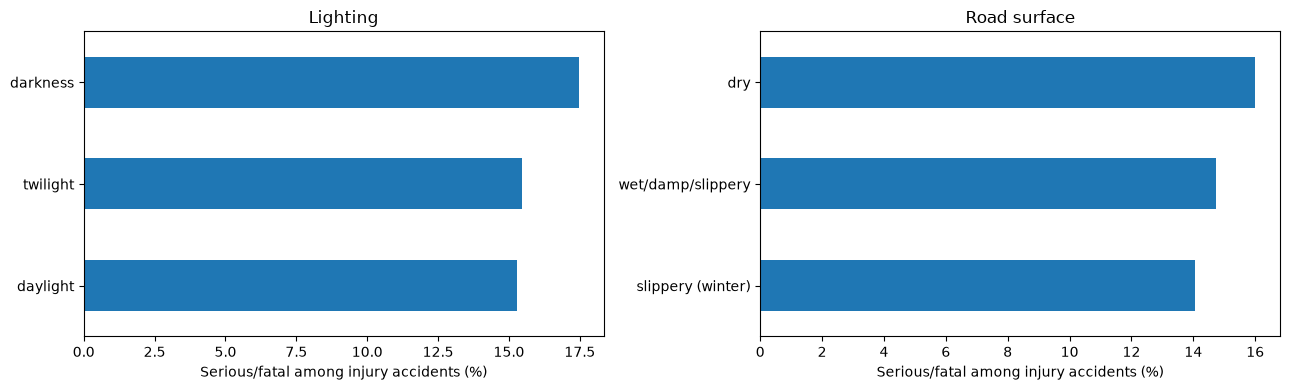

In [11]:
fig, axes = plt.subplots(1,2,figsize=(13,4))
for ax, column, title in zip(axes, ["light","road_condition"], ["Lighting", "Road surface"]):
    summary = train.groupby(column,dropna=False)["severe"].agg(accidents="size", severe_pct="mean")
    summary["severe_pct"] *= 100
    print("\n" + title)
    display(summary.sort_values("severe_pct",ascending=False).round(2))
    summary.sort_values("severe_pct")["severe_pct"].plot.barh(ax=ax)
    ax.set_title(title); ax.set_xlabel("Serious/fatal among injury accidents (%)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

### Which road users were involved?

We compare accidents involving cars, bicycles, pedestrians, motorcycles, trucks and other vehicles. **One accident may belong to several groups**, for example a car–bicycle accident.

,road_user,accidents,severe_pct
3,motorcycle,25665,24.63
4,truck,7619,21.37
2,pedestrian,16828,19.40
1,bicycle,62653,14.93
5,other_vehicle,27569,14.19
0,car,138400,13.80


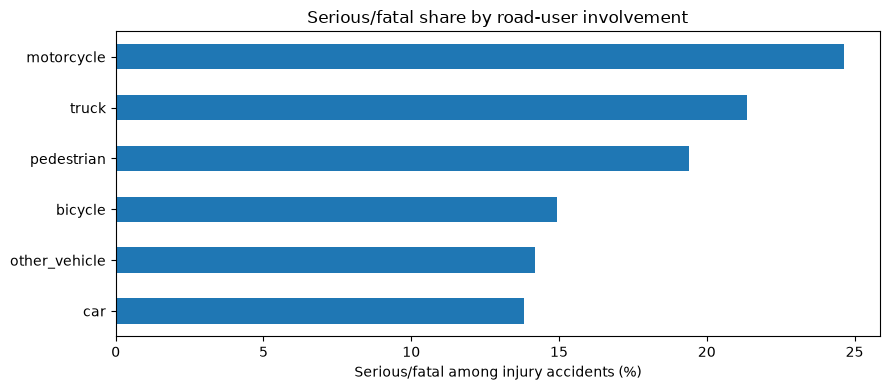

In [12]:
all_road_users = ["car", "bicycle", "pedestrian", "motorcycle", "truck", "other_vehicle"]
road_user_summary = pd.DataFrame([
    {"road_user": user, "accidents": len(part), "severe_pct": 100 * part["severe"].mean()}
    for user in all_road_users for part in [train.loc[train[user] == 1]]
]).sort_values("severe_pct", ascending=False)
display(road_user_summary.round(2))
road_user_summary.sort_values("severe_pct").plot.barh(x="road_user",y="severe_pct",legend=False,figsize=(9,4),title="Serious/fatal share by road-user involvement")
plt.xlabel("Serious/fatal among injury accidents (%)"); plt.ylabel(""); plt.tight_layout(); plt.show()

### Federal states and geography

We check whether the serious/fatal share varies across federal states. States differ in road networks, traffic and road-user mixes, so these are **descriptive comparisons**.

We keep precise longitude/latitude for modeling, but a map is not required here to understand state differences.

,accidents,severe_pct
state_name,,
Thüringen,3805,23.76
Sachsen,8895,21.15
Mecklenburg-Vorpommern,3419,19.89
Sachsen-Anhalt,5173,19.33
Brandenburg,5937,17.05
Bayern,32800,16.85
Rheinland-Pfalz,8911,16.72
Saarland,2198,16.61
Baden-Württemberg,22599,15.30


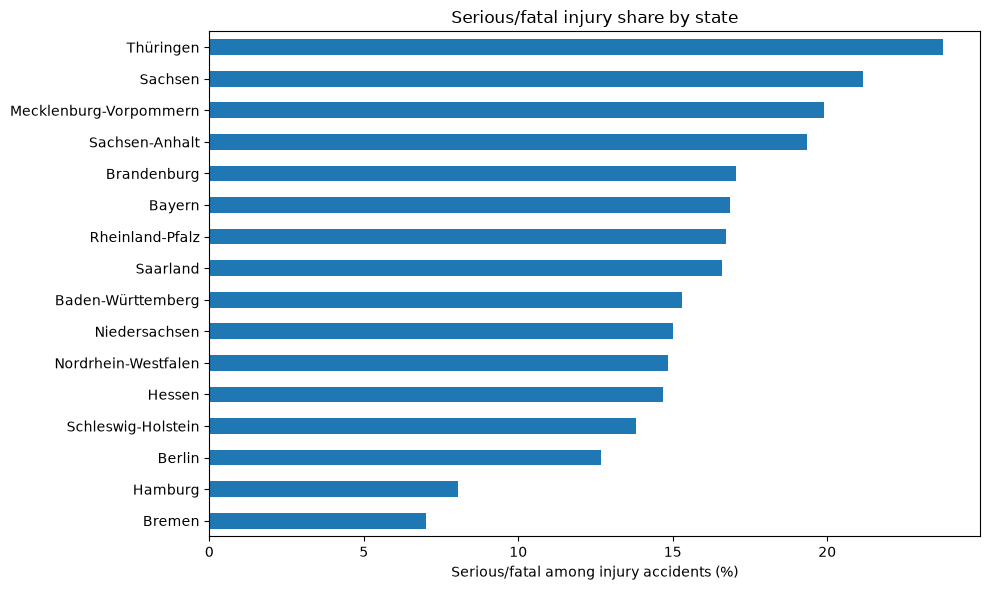

In [13]:
state_summary = train.groupby("state_name")["severe"].agg(accidents="size", severe_pct="mean").sort_values("severe_pct", ascending=False)
state_summary["severe_pct"] *= 100
display(state_summary.round(2))
state_summary.sort_values("severe_pct")["severe_pct"].plot.barh(figsize=(10,6),title="Serious/fatal injury share by state")
plt.xlabel("Serious/fatal among injury accidents (%)"); plt.ylabel(""); plt.tight_layout(); plt.show()

### Does nighttime differ by road user?

The overall nighttime pattern might hide differences between cars, cyclists and motorcycles. We compare their severity percentages in the same time periods. These road-user groups still overlap.

,road_user,time_group,accidents,severe_pct
0,car,Night (22–05),10776,19.22
1,car,Other hours,127624,13.34
2,bicycle,Night (22–05),3566,21.03
3,bicycle,Other hours,59087,14.57
4,pedestrian,Night (22–05),928,27.26
5,pedestrian,Other hours,15900,18.94
6,motorcycle,Night (22–05),1525,26.16
7,motorcycle,Other hours,24140,24.53
8,truck,Night (22–05),707,28.15
9,truck,Other hours,6912,20.67


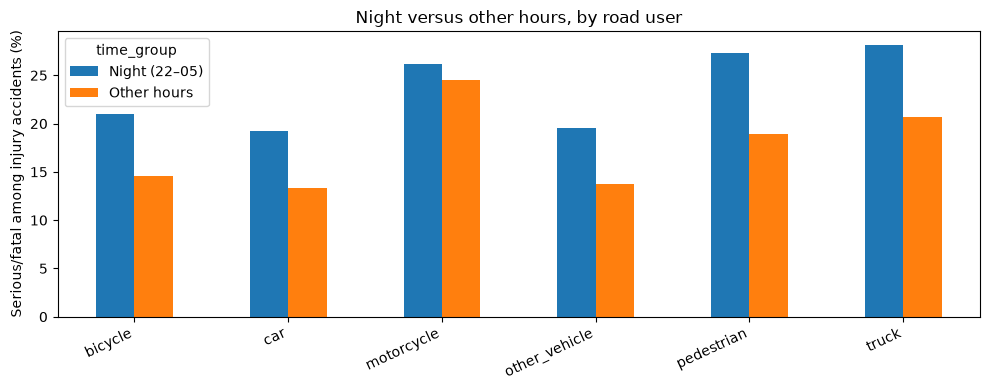

In [14]:
time_by_user = []
night_flag = (train["hour"] >= 22) | (train["hour"] < 6)
for user in all_road_users:
    part = train.loc[train[user] == 1, ["severe", "hour"]].copy()
    part["time_group"] = np.where((part["hour"] >= 22) | (part["hour"] < 6), "Night (22–05)", "Other hours")
    grouped = part.groupby("time_group")["severe"].agg(accidents="size", severe_pct="mean")
    for time_group, row in grouped.iterrows():
        time_by_user.append({"road_user":user,"time_group":time_group,"accidents":int(row["accidents"]),"severe_pct":row["severe_pct"]*100})
road_time_df = pd.DataFrame(time_by_user)
display(road_time_df.round(2))
road_time_df.pivot(index="road_user",columns="time_group",values="severe_pct").plot.bar(figsize=(10,4),title="Night versus other hours, by road user")
plt.ylabel("Serious/fatal among injury accidents (%)");plt.xlabel("");plt.xticks(rotation=25,ha="right");plt.tight_layout();plt.show()

### Road-user combinations and nighttime

A car-and-bicycle accident belongs to both groups in the earlier charts. Here we treat each exact combination as its own group. We compare night (22:00–05:59) with other hours and show the number of accidents beside the severe share.

The full table includes every combination. The chart shows the 12 most common combinations so it remains readable. Small groups can have unstable percentages; a high percentage based on a few accidents is not strong evidence.

accidents  \
combination                                time_group                 
bicycle                                    Night (22–05)       2174   
                                           Other hours        21778   
bicycle + motorcycle                       Night (22–05)         17   
                                           Other hours          676   
bicycle + motorcycle + other_vehicle       Other hours            2   
bicycle + other_vehicle                    Night (22–05)        167   
                                           Other hours         3684   
bicycle + pedestrian                       Night (22–05)        123   
                                           Other hours         2764   
bicycle + pedestrian + motorcycle          Other hours            1   
bicycle + pedestrian + other_vehicle       Other hours           19   
bicycle + truck                            Night (22–05)         17   
                                           Other hours          517   
bicycle + truck + other_vehicle            Other hours            4   
car                                        Night (22–05)       7079   
                                           Other hours        57402   
car + bicycle                              Night (22–05)       1059   
                                           Other hours        29342   
car + bicycle + motorcycle                 Night (22–05)          2   
                                           Other hours           39   
car + bicycle + other_vehicle              Night (22–05)          5   
                                           Other hours          159   
car + bicycle + pedestrian                 Night (22–05)          1   
                                           Other hours           82   
car + bicycle + pedestrian + other_vehicle Night (22–05)          1   
                                           Other hours            2   
car + bicycle + truck                      Other hours           17   
car + bicycle + truck + other_vehicle      Other hours            1   
car + motorcycle                           Night (22–05)        601   
                                           Other hours        12876   
car + motorcycle + other_vehicle           Night (22–05)          4   
                                           Other hours          136   
car + motorcycle + truck                   Night (22–05)          4   
                                           Other hours           54   
car + motorcycle + truck + other_vehicle   Other hours            5   
car + other_vehicle                        Night (22–05)        868   
                                           Other hours        12434   
car + pedestrian                           Night (22–05)        642   
                                           Other hours        10228   
car + pedestrian + motorcycle              Night (22–05)          1   
                                           Other hours           24   
car + pedestrian + other_vehicle           Night (22–05)          7   
                                           Other hours           77   
car + pedestrian + truck                   Night (22–05)          1   
                                           Other hours           12   
car + pedestrian + truck + other_vehicle   Night (22–05)          1   
                                           Other hours            1   
car + truck                                Night (22–05)        469   
                                           Other hours         4519   
car + truck + other_vehicle                Night (22–05)         31   
                                           Other hours          214   
motorcycle                                 Night (22–05)        803   
                                           Other hours         8517   
motorcycle + other_vehicle                 Night (22–05)         58   
                                           Other hours         1162   
motorcycle 

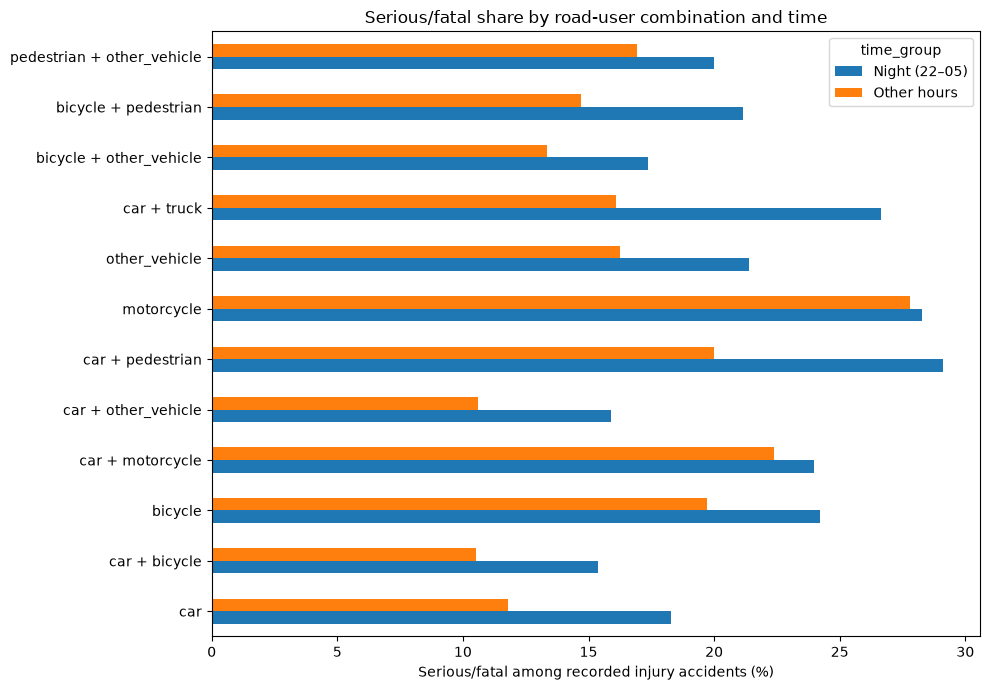

In [15]:
combination_users = ["car", "bicycle", "pedestrian", "motorcycle", "truck", "other_vehicle"]
assert train[combination_users].isin([0, 1]).all().all()
combination_eda = train[["severe", "hour"] + combination_users].copy()
combination_eda["combination"] = combination_eda[combination_users].apply(
    lambda row: " + ".join(user for user in combination_users if row[user] == 1)
    or "No listed road-user flag", axis=1,
)
combination_eda["time_group"] = np.where(
    (combination_eda["hour"] >= 22) | (combination_eda["hour"] < 6),
    "Night (22–05)", "Other hours",
)
combination_summary = combination_eda.groupby(
    ["combination", "time_group"]
)["severe"].agg(accidents="size", severe_pct="mean")
combination_summary["severe_pct"] *= 100
with pd.option_context("display.max_rows", None):
    display(combination_summary.round(2))
common_combinations = combination_eda["combination"].value_counts().head(12).index
combination_summary["severe_pct"].unstack().reindex(common_combinations).plot.barh(
    figsize=(10, 7), title="Serious/fatal share by road-user combination and time"
)
plt.xlabel("Serious/fatal among recorded injury accidents (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

### What did the full EDA tell us?

Look back at the tables and plots above and note which groups have higher or lower serious/fatal shares. **Do not assume** that the busiest time or state has the highest severity percentage.

We will use state, coordinates, time, lighting, road surface and road-user involvement as model inputs. We will also test the extra information from **city population density**. The models use no `accident_kind`, `accident_type`, identifiers, or outcome-derived features.

Our new density analysis comes next; it **adds to** this EDA rather than replacing it.

## EDA — Does severity change with population density?

We put **training accidents** into five groups, from places with fewer residents per square kilometre to places with more. We then calculate the percentage of accidents that were serious or fatal in each group.

Each group contains roughly the same **number of accidents**, not the same number of municipalities.

In [16]:
density_eda = train[["population_per_km2", "severe"]].copy()
density_eda["density_group"] = pd.qcut(
    density_eda["population_per_km2"], q=5, duplicates="drop"
)

density_summary = (
    density_eda.groupby("density_group", observed=True)
    .agg(accidents=("severe", "size"), severe_accidents=("severe", "sum"), severe_rate=("severe", "mean"))
    .reset_index()
)
density_summary["severe_pct"] = 100 * density_summary["severe_rate"]
display(density_summary.round(2))

,density_group,accidents,severe_accidents,severe_rate,severe_pct
0,"(1.999, 164.0]",38393,9151,0.24,23.84
1,"(164.0, 421.0]",38014,6889,0.18,18.12
2,"(421.0, 1029.0]",38263,5377,0.14,14.05
3,"(1029.0, 2141.0]",39070,4567,0.12,11.69
4,"(2141.0, 4844.0]",37228,4007,0.11,10.76


### Show the pattern in a chart

Each bar shows the share of serious/fatal injuries among recorded injury accidents in that density group. It does **not** show how likely people are to have an accident.

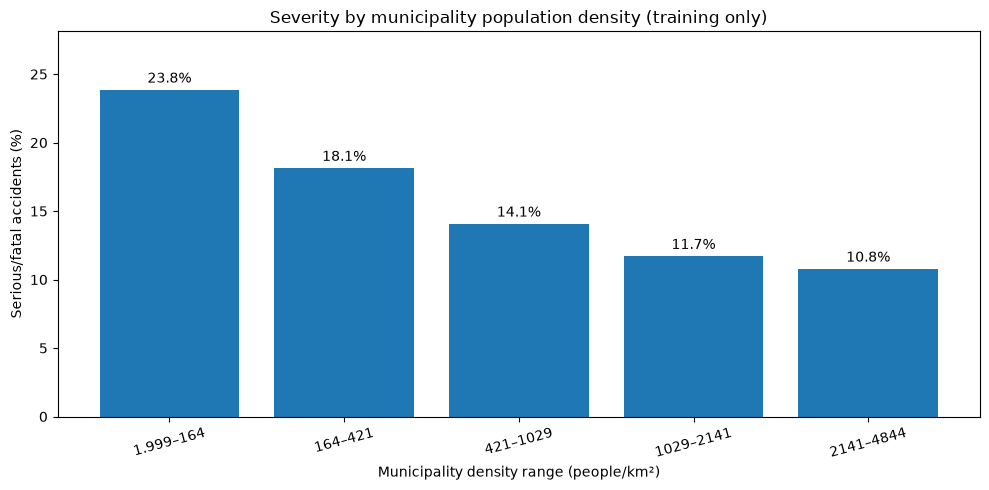

In [17]:
fig, ax = plt.subplots(figsize=(10, 5))
labels = [f"{interval.left:g}–{interval.right:g}" for interval in density_summary["density_group"]]
bars = ax.bar(labels, density_summary["severe_pct"])
for bar in bars:
    ax.annotate(f"{bar.get_height():.1f}%",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom", xytext=(0, 3), textcoords="offset points")
ax.set(xlabel="Municipality density range (people/km²)",
       ylabel="Serious/fatal accidents (%)",
       title="Severity by municipality population density (training only)")
ax.set_ylim(0, max(density_summary["severe_pct"]) * 1.18)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**What we found:** In our training data, **23.84%** of injury accidents were serious/fatal in the least densely populated group, compared with **10.76%** in the most densely populated group. That's a difference of about **13 percentage points**.

This makes population density worth testing in a model. It does **not** tell us why the difference exists. Road speed, infrastructure and other factors might also matter.

## Does the pattern also appear for different road users?

Maybe the density pattern is only caused by the mix of road users. Let's check accidents involving **cars, bicycles, pedestrians and motorcycles** separately.

An accident may appear in more than one group — for example, if it involved both a car and a bicycle.

In [21]:
road_users = ["car", "bicycle", "pedestrian", "motorcycle"]
density_road_user = train[["population_per_km2", "severe"] + road_users].copy()
density_bins = pd.IntervalIndex(density_eda["density_group"].cat.categories)
density_road_user["density_group"] = pd.cut(density_road_user["population_per_km2"], bins=density_bins)

results = []
for user in road_users:
    subset = density_road_user.loc[density_road_user[user] == 1]
    summary = subset.groupby("density_group", observed=True)["severe"].agg(
        accidents="size", severe_pct="mean"
    ).reset_index()
    summary["severe_pct"] *= 100
    summary["road_user"] = user
    results.append(summary)
road_user_density_summary = pd.concat(results, ignore_index=True)
display(road_user_density_summary.round(2))

,density_group,accidents,severe_pct,road_user
0,"(1.999, 164.0]",27470,20.97,car
1,"(164.0, 421.0]",27795,15.98,car
2,"(421.0, 1029.0]",27727,12.46,car
3,"(1029.0, 2141.0]",28075,10.02,car
4,"(2141.0, 4844.0]",27333,9.62,car
5,"(1.999, 164.0]",8516,24.00,bicycle
6,"(164.0, 421.0]",11629,18.51,bicycle
7,"(421.0, 1029.0]",13816,14.10,bicycle
8,"(1029.0, 2141.0]",15140,11.98,bicycle
9,"(2141.0, 4844.0]",13552,10.32,bicycle


### Plot the road-user results

Each line shows the serious/fatal percentage for accidents involving that road user, going from low to high population density.

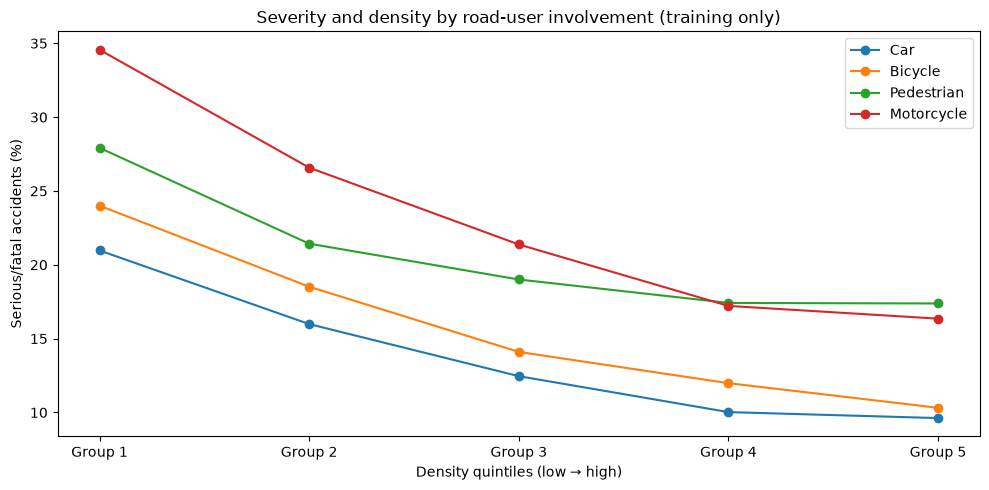

In [20]:
fig, ax = plt.subplots(figsize=(10, 5))
for user in road_users:
    part = road_user_density_summary.loc[road_user_density_summary["road_user"] == user]
    ax.plot(range(len(part)), part["severe_pct"].to_numpy(), marker="o", label=user.title())
ax.set_xticks(range(len(density_summary)))
ax.set_xticklabels([f"Group {i}" for i in range(1, len(density_summary) + 1)])
ax.set(xlabel="Density quintiles (low → high)", ylabel="Serious/fatal accidents (%)",
       title="Severity and density by road-user involvement (training only)")
ax.legend()
plt.tight_layout()
plt.show()

**What we found:** The share of serious/fatal accidents falls as density increases in all four groups:

- **Car:** 21.0% → 9.6%
- **Bicycle:** 24.0% → 10.3%
- **Pedestrian:** 27.9% → 17.4%
- **Motorcycle:** 34.6% → 16.4%

So the overall pattern is not limited to one road-user group. But these groups overlap, and we still cannot say that density *causes* the difference.

**Next:** Does adding density actually help a model make better predictions?

## Feature Engineering — What we carry into modeling

Feature engineering means turning existing information into useful model inputs. We derive weekend from weekday names and night from hour. The historical baseline uses the six road-user flags together to identify exact combinations.

For Logistic Regression and Random Forest, we compare the agreed 14 inputs with the same inputs plus population density. The modeling file explains how categories become numbers and why we shrink the very large density values before fitting.

## Findings for the Client

The saved training results show a clear pattern: the serious/fatal share falls from **23.84%** in the lowest-density group to **10.76%** in the highest. The middle groups are **18.12%, 14.05% and 11.69%**. A similar pattern appears within car, bicycle, pedestrian and motorcycle accidents.

This is a reason to investigate differences in road design, speeds and travel conditions. These results do not show that density itself causes injuries. The dataset does not contain all of those possible explanations.

Counts tell us how many injury accidents were recorded. Percentages tell us how serious those recorded accidents were. Neither tells us the chance of having an accident per trip or per kilometre travelled.

The other tables and charts remain above. Read their actual output before making claims about particular times, states or road conditions. The road-user combination table and chart have now also been calculated.

## Next Step

Open `02_accident_modeling.ipynb`. It checks the same updated file and split, then compares two simple benchmarks with four fitted models. No final test results are used to choose a model.

## References and Project Notes

Structure: supplied `03_eda-and-modeling(2).ipynb`. Requirements: supplied `01_assignment(2).md`. Project data: German Accident Atlas 2025, updated municipality-enriched CSV. Population source details and the municipality merge should be documented in the team's data-preparation record; they were not independently checked here.